In [5]:
import itertools as it
import pulp as pulp
import matplotlib.pyplot as pp
import numpy as np

def display_killersudoku( dica, sol = None, cages = None , savefig = False, namefile = 'default.png' ):
    pp.figure( figsize = (8, 8) )
    ax = pp.gca()

    L = int( np.round( dica.shape[0] ** 0.5 ) )

    ax.set_xticks( np.arange( 0, L ** 2 + 1, 1 ), minor = True )
    ax.set_yticks( np.arange( 0, L ** 2 + 1, 1 ), minor = True )
    ax.grid( which = 'minor' )
    ax.set_xticks( np.arange( 0, L ** 2 + 1, L ), [] * L, minor = False )
    ax.set_yticks( np.arange( 0, L ** 2 + 1, L ), [] * L, minor = False )
    ax.grid( which = 'major', linewidth = 2, color = 'k' )

    for i in range( L ** 2 ):
        for j in range( L ** 2 ):
            if dica[ i, j ] != 0:
                pp.text(
                    j + 0.5, L ** 2 - i - 0.5,
                    str( dica[ i, j ] ),
                    ha = 'center', va = 'center',
                    fontsize = 20, color = 'red'
                )

    if sol is not None:
        for i in range( L ** 2 ):
            for j in range( L ** 2 ):
                if dica[ i, j ] == 0:
                    pp.text(
                        j + 0.5, L ** 2 - i - 0.5,
                        str( sol[ i, j ] ),
                        ha = 'center', va = 'center',
                        fontsize = 20
                    )

    # Desenha as cages com linhas pontilhadas
    if cages is not None:
        epsilon = 0.05  # deslocamento leve das bordas
        for cage in cages:
            cage_cells = set( cage[ 'cells' ] )

            for ( i, j ) in cage_cells:
                x, y = j, L ** 2 - i - 1  # ajuste visual

                # Direções ( UP, DOWN, LEFT, RIGHT )
                neighbors = {
                    'up':    (i - 1, j),
                    'down':  (i + 1, j),
                    'left':  (i, j - 1),
                    'right': (i, j + 1),
                }

                for side, ( ni, nj ) in neighbors.items():
                    if ( ni, nj ) not in cage_cells:
                        if side == 'up':
                            ax.plot(
                                [ x + epsilon, x + 1 - epsilon ],
                                [ y + 1 - epsilon, y + 1 - epsilon ],
                                'k--', linewidth = 1
                            )
                        elif side == 'down':
                            ax.plot(
                                [ x + epsilon, x + 1 - epsilon ],
                                [ y + epsilon, y + epsilon ],
                                'k--', linewidth = 1
                            )
                        elif side == 'left':
                            ax.plot(
                                [ x + epsilon, x + epsilon ],
                                [ y + epsilon, y + 1 - epsilon ],
                                'k--', linewidth = 1
                            )
                        elif side == 'right':
                            ax.plot(
                                [ x + 1 - epsilon, x + 1 - epsilon ],
                                [ y + epsilon, y + 1 - epsilon ],
                                'k--', linewidth = 1
                            )

        # Inserir a soma no canto superior direito da célula de origem
        for cage in cages:
            if cage[ 'cells' ]:
                i, j = cage[ 'cells' ][0]
                x, y = j, L ** 2 - i - 1
                offset_x = 0.1
                offset_y = 0.9
                pp.text(
                    x + offset_x, y + offset_y,
                    str( cage[ 'sum' ] ),
                    fontsize = 10, color = 'black',
                    ha = 'left', va = 'top'
                )

    pp.xlim(0, L**2)
    pp.ylim(0, L**2)
    
    if savefig:
        pp.savefig(namefile, bbox_inches='tight', dpi=300)

    pp.show()

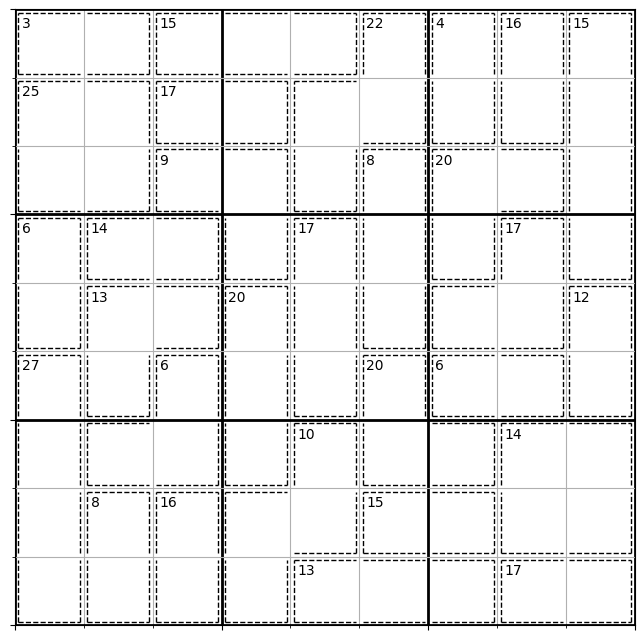

In [6]:
L=3

# Instância do problema
dica = np.zeros( ( L ** 2, L ** 2 ) )
cages = [
    {'cells': [(0, 0), (0, 1)], 'sum': 3},
    {'cells': [(0, 2), (0, 3), (0, 4)], 'sum': 15},
    {'cells': [(0, 5), (1, 5), (1, 4), (2, 4)], 'sum': 22},
    {'cells': [(0, 6), (1, 6)], 'sum': 4},
    {'cells': [(0, 7), (1, 7)], 'sum': 16},
    {'cells': [(0, 8), (1, 8), (2, 8), (3, 8)], 'sum': 15},
    {'cells': [(1, 0), (1, 1), (2, 1), (2, 0)], 'sum': 25},
    {'cells': [(1, 2), (1, 3)], 'sum': 17},
    {'cells': [(2, 2), (2, 3), (3, 3)], 'sum': 9},
    {'cells': [(2, 5), (3, 5), (4, 5)], 'sum': 8},
    {'cells': [(2, 6), (2, 7), (3, 6)], 'sum': 20},
    {'cells': [(3, 0), (4, 0)], 'sum': 6},
    {'cells': [(3, 1), (3, 2)], 'sum': 14},
    {'cells': [(3, 4), (4, 4), (5, 4)], 'sum': 17},
    {'cells': [(3, 7), (4, 7), (4, 6)], 'sum': 17},
    {'cells': [(4, 1), (4, 2), (5, 1)], 'sum': 13},
    {'cells': [(4, 3), (5, 3), (6, 3)], 'sum': 20},
    {'cells': [(4, 8), (5, 8)], 'sum': 12},
    {'cells': [(5, 0), (6, 0), (7, 0), (8, 0)], 'sum': 27},
    {'cells': [(5, 2), (6, 2), (6, 1)], 'sum': 6},
    {'cells': [(5, 5), (6, 5), (6, 6)], 'sum': 20},
    {'cells': [(5, 6), (5, 7)], 'sum': 6},
    {'cells': [(6, 4), (7, 4), (7, 3), (8, 3)], 'sum': 10},
    {'cells': [(6, 7), (7, 7), (7, 8), (6, 8)], 'sum': 14},
    {'cells': [(7, 1), (8, 1)], 'sum': 8},
    {'cells': [(7, 2), (8, 2)], 'sum': 16},
    {'cells': [(7, 5), (7, 6)], 'sum': 15},
    {'cells': [(8, 4), (8, 5), (8, 6)], 'sum': 13},
    {'cells': [(8, 7), (8, 8)], 'sum': 17}
]

display_killersudoku( dica = dica, sol = None, cages = cages, savefig = True, namefile = 'killersudoku.png' )

In [7]:
# Dimensão do Sudoku
L = 3

# Criando Variáveis do problema
x={}
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    x[i, j, k] = pulp.LpVariable( 
        name = f'x_{ i + 1 },{ j + 1 },{ k + 1 }',
        cat = pulp.LpBinary
    )

# Criando o modelo
p = pulp.LpProblem( 'KillerSudoku' )

# Todo quadrado contém apenas um número
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    p += pulp.lpSum( x[ i, j, k ] for k in range( L ** 2 ) ) == 1 

# Toda linha contém apenas uma ocorrência de cada número
for i, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += pulp.lpSum( x[ i, j, k ] for j in range( L ** 2 ) ) == 1

# Toda coluna contém apenas uma ocorrência de cada número
for j, k in it.product( range( L ** 2 ), repeat = 2 ):
    p += pulp.lpSum( x[ i , j, k ] for i in range( L ** 2 ) ) == 1

# Todo subquadrado L x L contém apenas uma ocorrência de cada número
for I, J, k in it.product( range( L ), range( L ), range( L ** 2 ) ):
    p += pulp.lpSum( 
        x[ I * L + i, J * L + j, k ] for i, j in it.product( range( L ), repeat = 2 )
    ) == 1

# Toda gaiola contém NO MÁXIMO uma ocorrência de cada número
for cage in cages:
    for k in range( L ** 2 ):
        p += pulp.lpSum(
            x[ i, j, k ] for ( i, j ) in cage[ 'cells' ]
        ) <= 1
    
# Toda gaiola deve conter números que somam S
for cage in cages:
    p += pulp.lpSum(
        ( k + 1 ) * x[ i, j, k ] for ( ( i, j ), k ) in it.product( cage[ 'cells' ], range( L ** 2 ) )
    ) == cage[ 'sum' ]

# Aplicar as dicas na solução inicial
for i, j in it.product( range( L ** 2 ), repeat = 2 ):
    if dica[ i, j ] != 0:
        p += ( x[ i, j, dica[ i, j ] - 1 ] == 1 )

p.solve(
    pulp.GUROBI( msg = False )
)

print( pulp.LpStatus[ p.status ] )

Optimal


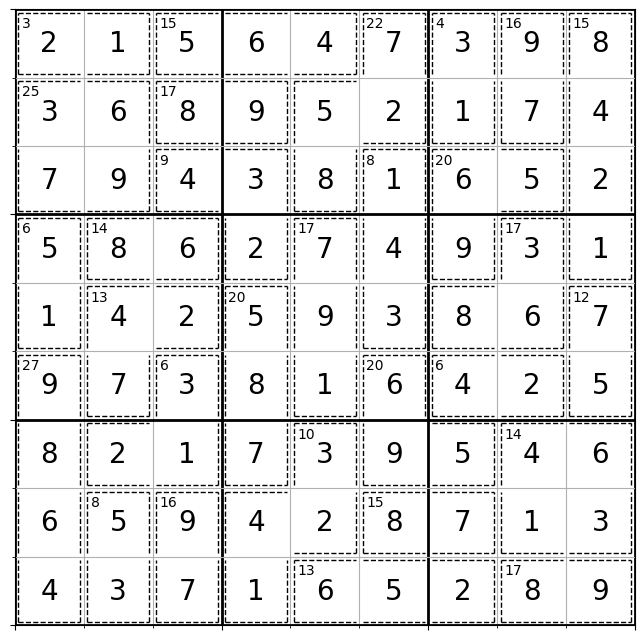

In [8]:
solution = np.empty( ( L ** 2, L ** 2 ), dtype = int )
for i, j, k in it.product( range( L ** 2 ), repeat = 3 ):
    if x[ i, j, k ].value() > 1e-6:
        solution[ i, j ] = k + 1
        
display_killersudoku( np.zeros( ( L ** 2, L ** 2 ) ), sol = solution, cages = cages, savefig = True, namefile = 'solution_killersudoku.png' )